In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [3]:
df= pd.read_csv("ambulance_eta.csv")
df

,Unnamed: 0,Hour,Is_Rush_Hour,Is_Night,Traffic_Level,Weather_Severity,Weather_Impact_Level,Distance_to_Incident,Ambulance_Speed,Base_Travel_Time_Min,Traffic_x_Distance,Weather_x_Distance,Is_Human_Dispatch,Ambulance_ETA_Min,Region_Type,Road_Type,Emergency_Level
0,0,0.0,0,1,3.0,NaN,0.0,41.57,47.96,52.01,124.71,41.57,1.0,115.08,Suburban,Unpaved Road,Minor
1,1,1.0,0,1,2.0,0.0,2.0,34.72,56.41,36.93,69.44,0.00,1.0,49.04,Urban,Local Road,Major
2,2,1.0,0,1,1.0,0.0,0.0,11.91,30.67,23.30,11.91,0.00,0.0,16.74,Rural,Highway,Minor
3,3,1.0,0,1,2.0,1.0,0.0,10.15,50.58,12.04,20.30,10.15,1.0,26.50,Urban,Highway,Minor
4,4,2.0,0,1,1.0,0.0,1.0,28.47,51.76,33.00,28.47,0.00,0.0,38.83,Urban,Highway,Minor
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100400,100400,19.0,1,0,2.0,0.0,2.0,22.21,44.34,30.05,44.42,0.00,1.0,43.57,Rural,Local Road,Minor
100401,100401,19.0,1,0,1.0,0.0,1.0,41.20,28.30,87.35,41.20,0.00,1.0,84.08,Suburban,Highway,Critical
100402,100402,20.0,0,0,1.0,0.0,1.0,27.64,49.97,33.19,27.64,0.00,1.0,51.37,Suburban,Unpaved Road,Minor
100403,100403,21.0,0,0,1.0,0.0,1.0,22.98,49.40,27.91,22.98,0.00,1.0,37.48,Urban,Highway,Minor


In [4]:
df.shape

(100405, 17)

In [5]:
df = df.drop(df.columns[0],axis=1)

In [6]:
df.head()

,Hour,Is_Rush_Hour,Is_Night,Traffic_Level,Weather_Severity,Weather_Impact_Level,Distance_to_Incident,Ambulance_Speed,Base_Travel_Time_Min,Traffic_x_Distance,Weather_x_Distance,Is_Human_Dispatch,Ambulance_ETA_Min,Region_Type,Road_Type,Emergency_Level
0,0.0,0,1,3.0,NaN,0.0,41.57,47.96,52.01,124.71,41.57,1.0,115.08,Suburban,Unpaved Road,Minor
1,1.0,0,1,2.0,0.0,2.0,34.72,56.41,36.93,69.44,0.00,1.0,49.04,Urban,Local Road,Major
2,1.0,0,1,1.0,0.0,0.0,11.91,30.67,23.30,11.91,0.00,0.0,16.74,Rural,Highway,Minor
3,1.0,0,1,2.0,1.0,0.0,10.15,50.58,12.04,20.30,10.15,1.0,26.50,Urban,Highway,Minor
4,2.0,0,1,1.0,0.0,1.0,28.47,51.76,33.00,28.47,0.00,0.0,38.83,Urban,Highway,Minor


In [7]:
df.isna().sum()

Hour                     370
Is_Rush_Hour               0
Is_Night                   0
Traffic_Level           1226
Weather_Severity         990
Weather_Impact_Level     816
Distance_to_Incident    1046
Ambulance_Speed         1203
Base_Travel_Time_Min     623
Traffic_x_Distance       636
Weather_x_Distance       630
Is_Human_Dispatch        571
Ambulance_ETA_Min        556
Region_Type              743
Road_Type                922
Emergency_Level          621
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(405)

In [9]:
df=df.drop_duplicates()

In [10]:
df.shape

(100000, 16)

In [11]:
df.info()

<class 'pandas.DataFrame'>
Index: 100000 entries, 0 to 100404
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Hour                  99630 non-null   float64
 1   Is_Rush_Hour          100000 non-null  int64  
 2   Is_Night              100000 non-null  int64  
 3   Traffic_Level         98777 non-null   float64
 4   Weather_Severity      99011 non-null   float64
 5   Weather_Impact_Level  99186 non-null   float64
 6   Distance_to_Incident  98956 non-null   float64
 7   Ambulance_Speed       98802 non-null   float64
 8   Base_Travel_Time_Min  99378 non-null   float64
 9   Traffic_x_Distance    99366 non-null   float64
 10  Weather_x_Distance    99373 non-null   float64
 11  Is_Human_Dispatch     99432 non-null   float64
 12  Ambulance_ETA_Min     99444 non-null   float64
 13  Region_Type           99261 non-null   str    
 14  Road_Type             99083 non-null   str    
 15  Emergency_Level 

In [12]:
df.describe()

,Hour,Is_Rush_Hour,Is_Night,Traffic_Level,Weather_Severity,Weather_Impact_Level,Distance_to_Incident,Ambulance_Speed,Base_Travel_Time_Min,Traffic_x_Distance,Weather_x_Distance,Is_Human_Dispatch,Ambulance_ETA_Min
count,99630.000000,100000.000000,100000.000000,98777.000000,99011.000000,99186.000000,98956.000000,98802.000000,99378.000000,99366.000000,99373.000000,99432.000000,99444.000000
mean,11.566697,0.295890,0.331650,1.605252,0.247922,0.348991,26.516515,40.169124,43.551051,40.743550,6.351729,0.799199,52.680422
std,7.245649,0.461044,0.470808,0.696824,0.534208,0.569146,32.890169,10.559746,134.829558,29.904391,16.022208,0.400601,36.864356
min,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-5.000000,-1.000000,-3.000000,0.900000,0.000000,0.000000,-12.500000
25%,6.000000,0.000000,0.000000,1.000000,0.000000,0.000000,13.130000,34.190000,19.680000,17.990000,0.000000,1.000000,26.710000
50%,12.000000,0.000000,0.000000,1.000000,0.000000,0.000000,25.485000,39.830000,38.090000,34.545000,0.000000,1.000000,47.765000
75%,18.000000,1.000000,1.000000,2.000000,0.000000,1.000000,37.690000,45.660000,56.930000,54.120000,0.000000,1.000000,71.470000
max,99.000000,2.000000,1.000000,9.000000,2.000000,2.000000,999.990000,250.000000,5000.000000,169.050000,107.880000,1.000000,1174.690000


In [13]:
df.describe(include="object")

C:\Users\pushk\AppData\Local\Temp\ipykernel_4944\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Region_Type,Road_Type,Emergency_Level
count,99261,99083,99381
unique,14,14,13
top,Urban,Highway,Minor
freq,67740,57586,67687


# Data Overview

In [14]:
num_col = df.describe().columns
num_col

Index(['Hour', 'Is_Rush_Hour', 'Is_Night', 'Traffic_Level', 'Weather_Severity',
       'Weather_Impact_Level', 'Distance_to_Incident', 'Ambulance_Speed',
       'Base_Travel_Time_Min', 'Traffic_x_Distance', 'Weather_x_Distance',
       'Is_Human_Dispatch', 'Ambulance_ETA_Min'],
      dtype='str')

In [15]:
non_num_col = df.describe(include="object").columns
non_num_col

C:\Users\pushk\AppData\Local\Temp\ipykernel_4944\3325412589.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  non_num_col = df.describe(include="object").columns


Index(['Region_Type', 'Road_Type', 'Emergency_Level'], dtype='str')

In [16]:
df["Region_Type"].value_counts()

Region_Type
Urban         67740
Suburban      19204
Rural          9606
 Urban          579
urban           573
URBAN           571
Unknown         252
 Suburban       161
SUBURBAN        156
suburban        146
rural            88
RURAL            75
 Rural           70
Sub-urban        40
Name: count, dtype: int64

In [17]:
df["Road_Type"].value_counts()

Road_Type
Highway           57586
Local Road        29034
Unpaved Road       9596
 Highway            511
HIGHWAY             492
highway             489
Unknown             312
LOCAL ROAD          258
local road          243
 Local Road         239
UNPAVED ROAD        100
 Unpaved Road        93
unpaved road         82
Local Rd             48
Name: count, dtype: int64

In [18]:
df["Emergency_Level"].value_counts()

Emergency_Level
Minor         67687
Major         19295
Critical       9731
MINOR           627
minor           565
 Minor          550
Unknown         200
 Major          170
MAJOR           161
major           157
critical         86
CRITICAL         78
 Critical        74
Name: count, dtype: int64

In [19]:
df["Weather_Severity"].value_counts()

Weather_Severity
0.0    79361
1.0    14753
2.0     4897
Name: count, dtype: int64

In [20]:
df["Weather_Impact_Level"].value_counts()

Weather_Impact_Level
0.0    69368
1.0    25021
2.0     4797
Name: count, dtype: int64

In [21]:
df["Is_Human_Dispatch"].value_counts()


Is_Human_Dispatch
1.0    79466
0.0    19966
Name: count, dtype: int64

In [22]:
df["Distance_to_Incident"].min()

np.float64(-5.0)

In [23]:
df["Ambulance_ETA_Min"].min()

np.float64(-12.5)

In [24]:
df["Ambulance_ETA_Min"].max()

np.float64(1174.69)

In [25]:
col_to_check  = ["Distance_to_Incident", "Ambulance_Speed", "Base_Travel_Time_Min","Traffic_x_Distance", "Weather_x_Distance", "Ambulance_ETA_Min"]

# Data Cleaning

In [26]:
for c in non_num_col:
    df[c] = df[c].str.strip().str.title()

In [27]:
df[non_num_col]

,Region_Type,Road_Type,Emergency_Level
0,Suburban,Unpaved Road,Minor
1,Urban,Local Road,Major
2,Rural,Highway,Minor
3,Urban,Highway,Minor
4,Urban,Highway,Minor
...,...,...,...
100400,Rural,Local Road,Minor
100401,Suburban,Highway,Critical
100402,Suburban,Unpaved Road,Minor
100403,Urban,Highway,Minor


In [28]:
df[non_num_col].nunique()

Region_Type        5
Road_Type          5
Emergency_Level    4
dtype: int64

In [29]:
df["Region_Type"].value_counts()

Region_Type
Urban        69463
Suburban     19667
Rural         9839
Unknown        252
Sub-Urban       40
Name: count, dtype: int64

In [30]:
df["Road_Type"].value_counts()

Road_Type
Highway         59078
Local Road      29774
Unpaved Road     9871
Unknown           312
Local Rd           48
Name: count, dtype: int64

In [31]:
df["Emergency_Level"].value_counts()

Emergency_Level
Minor       69429
Major       19783
Critical     9969
Unknown       200
Name: count, dtype: int64

In [32]:
df["Road_Type"] = df["Road_Type"].replace({"Local Rd": "Local Road"})
df["Region_Type"] = df["Region_Type"].replace({"Sub-Urban": "Suburban"})

In [33]:
df = df.replace(["", "Unknown", "N/A", "NA", "null", "?"], np.nan)

In [34]:
df.isna().sum()

Hour                     370
Is_Rush_Hour               0
Is_Night                   0
Traffic_Level           1223
Weather_Severity         989
Weather_Impact_Level     814
Distance_to_Incident    1044
Ambulance_Speed         1198
Base_Travel_Time_Min     622
Traffic_x_Distance       634
Weather_x_Distance       627
Is_Human_Dispatch        568
Ambulance_ETA_Min        556
Region_Type              991
Road_Type               1229
Emergency_Level          819
dtype: int64

In [35]:
for c in non_num_col:
    print(df[c].value_counts(dropna=False), "\n")

Region_Type
Urban       69463
Suburban    19707
Rural        9839
NaN           991
Name: count, dtype: int64 

Road_Type
Highway         59078
Local Road      29822
Unpaved Road     9871
NaN              1229
Name: count, dtype: int64 

Emergency_Level
Minor       69429
Major       19783
Critical     9969
NaN           819
Name: count, dtype: int64 



In [36]:
df.loc[(df["Distance_to_Incident"] <= 0) | (df["Distance_to_Incident"] > 80), "Distance_to_Incident"] = np.nan

In [37]:
df.loc[(df["Ambulance_Speed"] <= 0) | (df["Ambulance_Speed"] > 100), "Ambulance_Speed"] = np.nan

In [38]:
df.loc[~df["Hour"].between(0, 23), "Hour"] = np.nan

In [39]:
df.loc[~df["Traffic_Level"].isin([1, 2, 3]), "Traffic_Level"] = np.nan


In [40]:
df.loc[~df["Is_Rush_Hour"].isin([0, 1]), "Is_Rush_Hour"] = np.nan

In [41]:
df.loc[(df["Base_Travel_Time_Min"] <= 0) | (df["Base_Travel_Time_Min"] > 300), "Base_Travel_Time_Min"] = np.nan

In [42]:
df.loc[(df["Ambulance_ETA_Min"] <= 0) | (df["Ambulance_ETA_Min"] > 180), "Ambulance_ETA_Min"] = np.nan

In [43]:
df.isna().sum()

Hour                     562
Is_Rush_Hour             211
Is_Night                   0
Traffic_Level           1417
Weather_Severity         989
Weather_Impact_Level     814
Distance_to_Incident    1365
Ambulance_Speed         1443
Base_Travel_Time_Min     829
Traffic_x_Distance       634
Weather_x_Distance       627
Is_Human_Dispatch        568
Ambulance_ETA_Min        868
Region_Type              991
Road_Type               1229
Emergency_Level          819
dtype: int64

In [44]:
df.loc[df["Ambulance_ETA_Min"].isna()]

,Hour,Is_Rush_Hour,Is_Night,Traffic_Level,Weather_Severity,Weather_Impact_Level,Distance_to_Incident,Ambulance_Speed,Base_Travel_Time_Min,Traffic_x_Distance,Weather_x_Distance,Is_Human_Dispatch,Ambulance_ETA_Min,Region_Type,Road_Type,Emergency_Level
27,14.0,0.0,0,1.0,0.0,0.0,45.46,36.02,75.72,45.46,0.00,0.0,NaN,Urban,Highway,Minor
30,16.0,1.0,0,1.0,0.0,1.0,32.36,25.11,77.32,32.36,0.00,1.0,NaN,Urban,Highway,Major
43,23.0,0.0,1,1.0,2.0,1.0,34.72,39.48,52.77,34.72,69.44,1.0,NaN,Suburban,Highway,NaN
278,20.0,0.0,0,1.0,0.0,0.0,13.62,41.99,19.46,13.62,0.00,0.0,NaN,Urban,Highway,Major
447,10.0,0.0,0,1.0,0.0,1.0,29.56,53.78,32.98,29.56,0.00,1.0,NaN,Urban,Highway,Minor
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100071,8.0,1.0,0,1.0,0.0,0.0,10.84,48.97,13.28,10.84,0.00,0.0,NaN,Urban,Unpaved Road,Minor
100145,12.0,0.0,0,1.0,0.0,1.0,39.45,24.01,98.58,39.45,0.00,1.0,NaN,Suburban,Highway,Minor
100177,10.0,0.0,0,1.0,0.0,0.0,40.68,19.95,122.35,40.68,0.00,1.0,NaN,Suburban,Highway,Critical
100196,23.0,0.0,1,2.0,0.0,0.0,38.05,35.86,63.66,76.10,0.00,1.0,NaN,Suburban,Local Road,Major


In [45]:
df.loc[df["Distance_to_Incident"].isna()]

,Hour,Is_Rush_Hour,Is_Night,Traffic_Level,Weather_Severity,Weather_Impact_Level,Distance_to_Incident,Ambulance_Speed,Base_Travel_Time_Min,Traffic_x_Distance,Weather_x_Distance,Is_Human_Dispatch,Ambulance_ETA_Min,Region_Type,Road_Type,Emergency_Level
80,21.0,0.0,0,2.0,0.0,0.0,NaN,47.01,20.10,31.50,0.0,1.0,37.34,Suburban,Local Road,Major
219,7.0,1.0,0,1.0,0.0,0.0,NaN,26.67,31.38,13.95,0.0,1.0,34.03,Urban,Highway,Major
243,16.0,1.0,0,1.0,0.0,0.0,NaN,45.88,12.24,9.36,0.0,1.0,15.42,Urban,Highway,Minor
325,6.0,0.0,0,1.0,0.0,0.0,NaN,51.47,12.87,11.04,0.0,1.0,19.20,Urban,Local Road,Minor
361,6.0,0.0,0,1.0,NaN,0.0,NaN,45.02,46.03,34.54,0.0,1.0,45.34,Urban,Local Road,Minor
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100125,2.0,0.0,1,1.0,0.0,0.0,NaN,36.91,41.19,25.34,0.0,1.0,47.82,Urban,Highway,Minor
100175,4.0,0.0,1,1.0,0.0,0.0,NaN,33.53,41.00,22.91,0.0,0.0,37.11,Urban,Highway,Minor
100285,21.0,0.0,0,2.0,1.0,0.0,NaN,46.05,20.98,32.20,16.1,1.0,32.27,Urban,Local Road,Minor
100330,1.0,0.0,1,2.0,0.0,1.0,NaN,46.97,31.81,49.80,0.0,1.0,39.51,Urban,Highway,Major


In [46]:
df  =df.dropna()
df.isna().sum()

Hour                    0
Is_Rush_Hour            0
Is_Night                0
Traffic_Level           0
Weather_Severity        0
Weather_Impact_Level    0
Distance_to_Incident    0
Ambulance_Speed         0
Base_Travel_Time_Min    0
Traffic_x_Distance      0
Weather_x_Distance      0
Is_Human_Dispatch       0
Ambulance_ETA_Min       0
Region_Type             0
Road_Type               0
Emergency_Level         0
dtype: int64

In [47]:
df.info()

<class 'pandas.DataFrame'>
Index: 87425 entries, 1 to 100404
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Hour                  87425 non-null  float64
 1   Is_Rush_Hour          87425 non-null  float64
 2   Is_Night              87425 non-null  int64  
 3   Traffic_Level         87425 non-null  float64
 4   Weather_Severity      87425 non-null  float64
 5   Weather_Impact_Level  87425 non-null  float64
 6   Distance_to_Incident  87425 non-null  float64
 7   Ambulance_Speed       87425 non-null  float64
 8   Base_Travel_Time_Min  87425 non-null  float64
 9   Traffic_x_Distance    87425 non-null  float64
 10  Weather_x_Distance    87425 non-null  float64
 11  Is_Human_Dispatch     87425 non-null  float64
 12  Ambulance_ETA_Min     87425 non-null  float64
 13  Region_Type           87425 non-null  str    
 14  Road_Type             87425 non-null  str    
 15  Emergency_Level       87425 non-nu

In [48]:
df.describe()

,Hour,Is_Rush_Hour,Is_Night,Traffic_Level,Weather_Severity,Weather_Impact_Level,Distance_to_Incident,Ambulance_Speed,Base_Travel_Time_Min,Traffic_x_Distance,Weather_x_Distance,Is_Human_Dispatch,Ambulance_ETA_Min
count,87425.000000,87425.000000,87425.000000,87425.000000,87425.000000,87425.000000,87425.000000,87425.000000,87425.000000,87425.000000,87425.000000,87425.000000,87425.000000
mean,11.526074,0.292262,0.330947,1.599131,0.247938,0.349454,25.467196,40.014035,40.033167,40.723663,6.336461,0.799257,52.014220
std,6.912467,0.454805,0.470557,0.664450,0.533959,0.569365,14.203848,8.509029,24.765738,29.882096,15.991615,0.400559,31.864912
min,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.900000,0.500000,0.960000,0.900000,0.000000,0.000000,2.000000
25%,6.000000,0.000000,0.000000,1.000000,0.000000,0.000000,13.130000,34.210000,19.710000,17.940000,0.000000,1.000000,26.740000
50%,12.000000,0.000000,0.000000,1.000000,0.000000,0.000000,25.450000,39.840000,38.040000,34.600000,0.000000,1.000000,47.690000
75%,18.000000,1.000000,1.000000,2.000000,0.000000,1.000000,37.660000,45.640000,56.890000,54.120000,0.000000,1.000000,71.320000
max,23.000000,1.000000,1.000000,3.000000,2.000000,2.000000,58.300000,80.150000,186.070000,169.050000,107.560000,1.000000,175.560000


# Univariate Analysis 

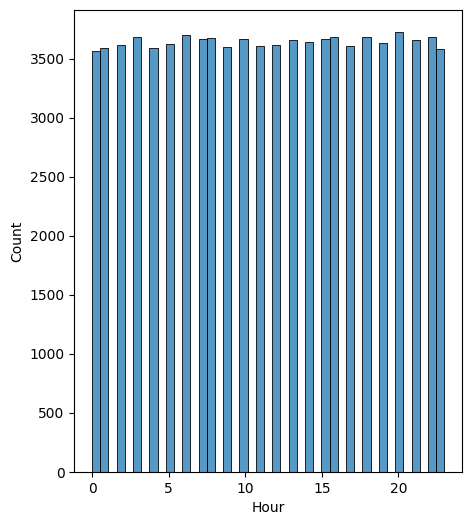

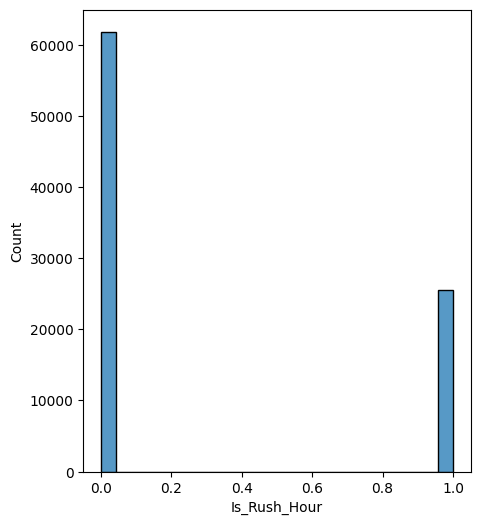

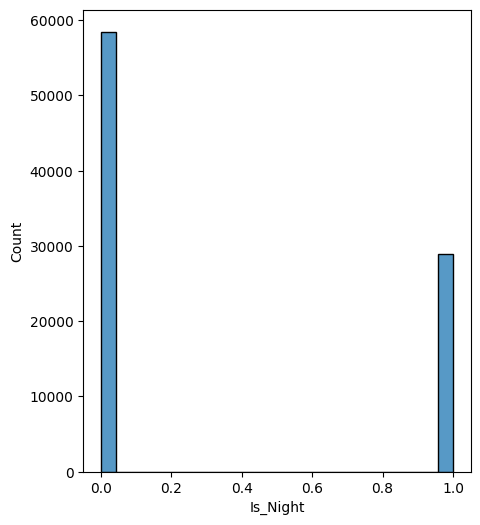

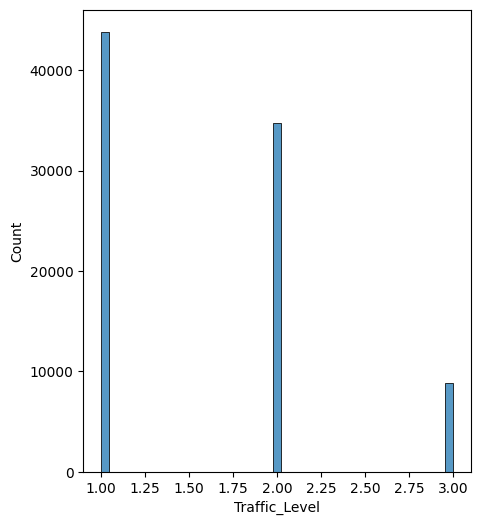

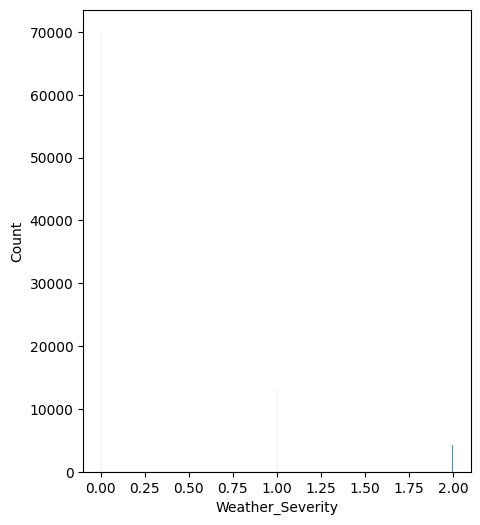

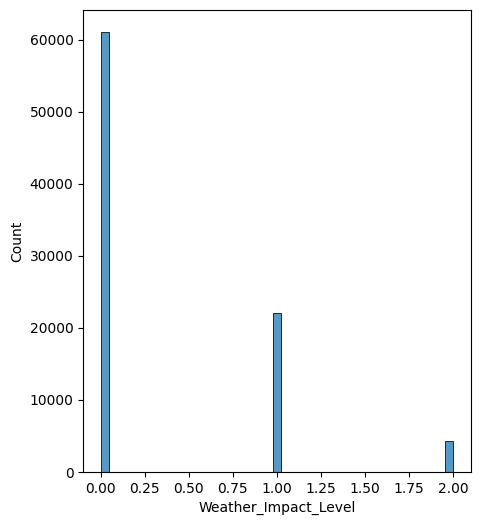

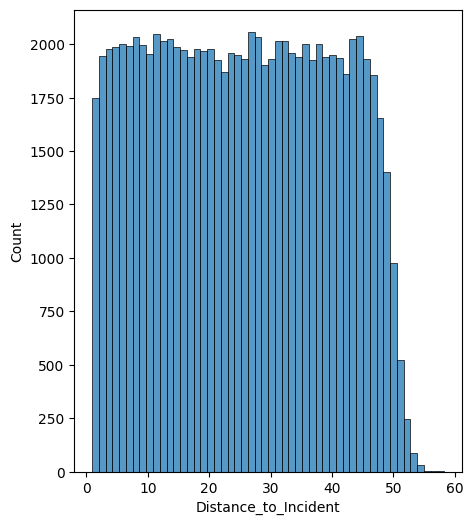

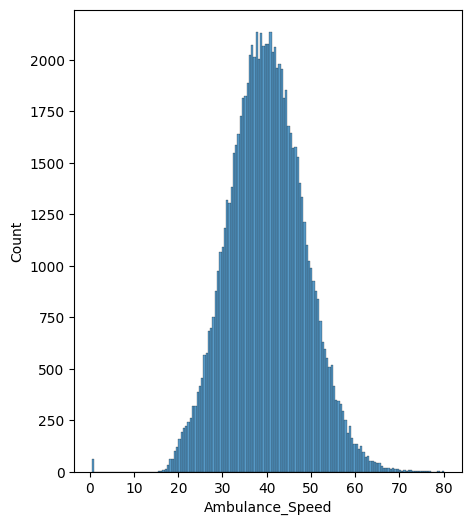

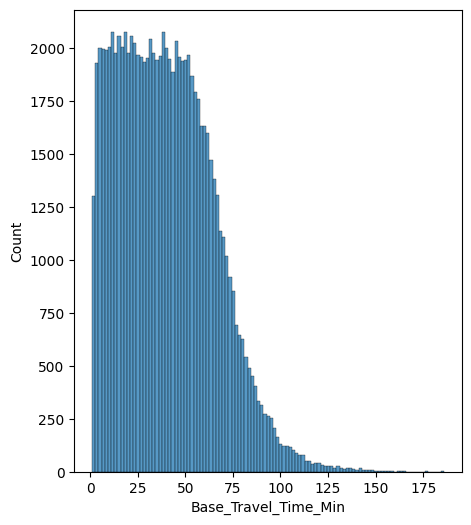

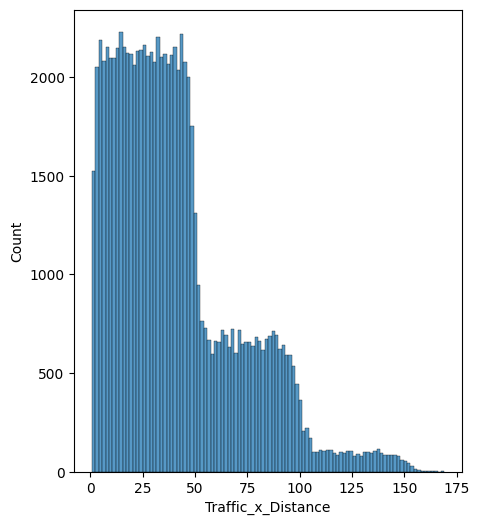

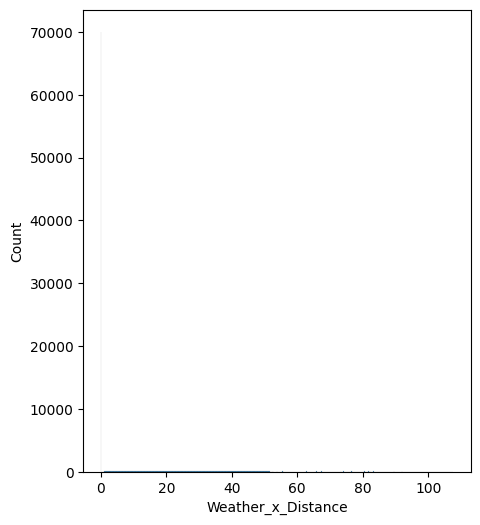

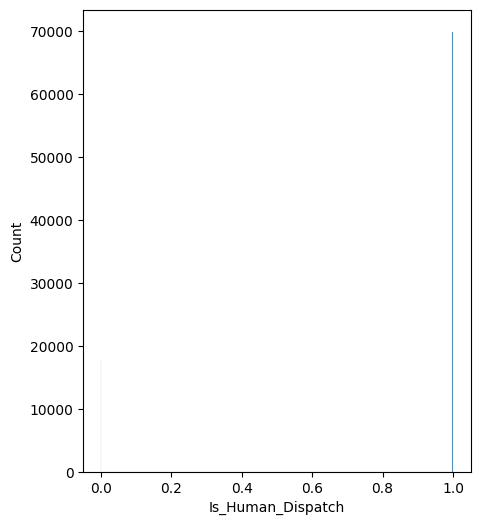

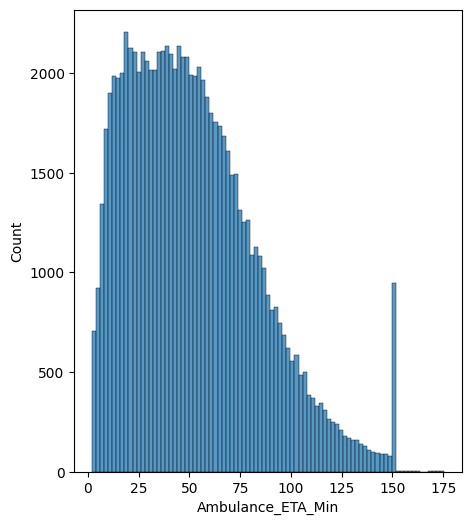

In [49]:
for i in num_col:
    plt.figure(figsize=(5, 6))
    sns.histplot(df[i])
    plt.show()

## insights:

1. even distribution across all 24 hours
2. most of ambulance transit occurs during off-peak traffic conditions.
3. reflecting a 2:1 daytime emergency volume ratio
4. severe traffic congestion occurs in only ~10% of trips
5. rare severe weather events
6. Shows a uniform spread from 2 km to 48 km
7. ambulance_speed : symmetric but peak around the 42 kmph
8. Base_Travel_Time_Min: right-skewed distribution concentrating between 5 and 60 minute
9. right-skewed peak between 15 and 60 minutes

In [50]:
df.columns

Index(['Hour', 'Is_Rush_Hour', 'Is_Night', 'Traffic_Level', 'Weather_Severity',
       'Weather_Impact_Level', 'Distance_to_Incident', 'Ambulance_Speed',
       'Base_Travel_Time_Min', 'Traffic_x_Distance', 'Weather_x_Distance',
       'Is_Human_Dispatch', 'Ambulance_ETA_Min', 'Region_Type', 'Road_Type',
       'Emergency_Level'],
      dtype='str')

In [51]:
col_to_check = ["Distance_to_Incident","Ambulance_Speed","Base_Travel_Time_Min","Traffic_x_Distance","Weather_x_Distance","Ambulance_ETA_Min"]

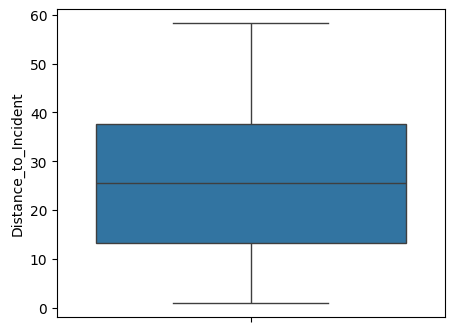

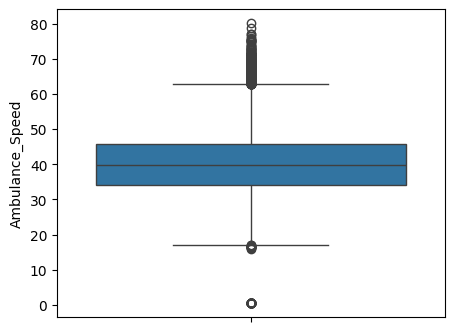

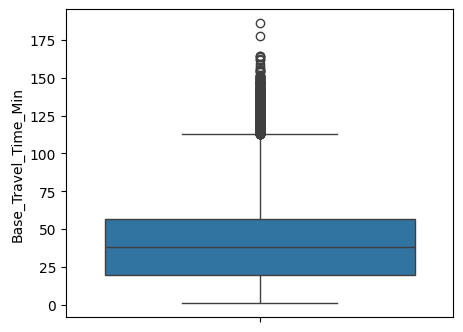

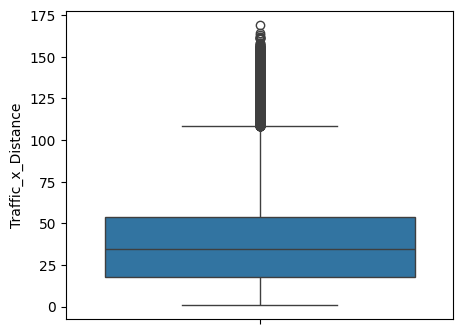

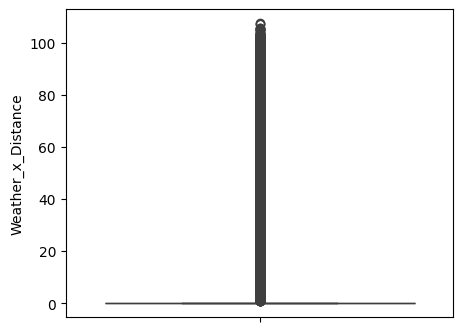

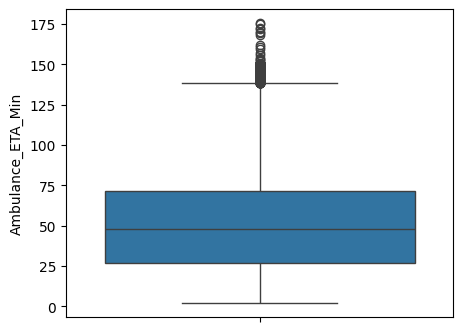

In [52]:
for i in col_to_check:
    plt.figure(figsize=(5, 4))
    sns.boxplot(df[i])
    plt.show()

1. distance is spread evenly from 1 to 50 km 
2. speed is centered around 40 km/h 
3. ambulance eta is right skewed, 
4. most calls are under 70 minutes and a few go up to 150

In [53]:
df.describe(include="object").columns

C:\Users\pushk\AppData\Local\Temp\ipykernel_4944\3492428972.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object").columns


Index(['Region_Type', 'Road_Type', 'Emergency_Level'], dtype='str')

In [54]:
cat_cols = ['Region_Type', 'Road_Type', 'Emergency_Level',"Traffic_Level", "Weather_Severity", "Weather_Impact_Level"]

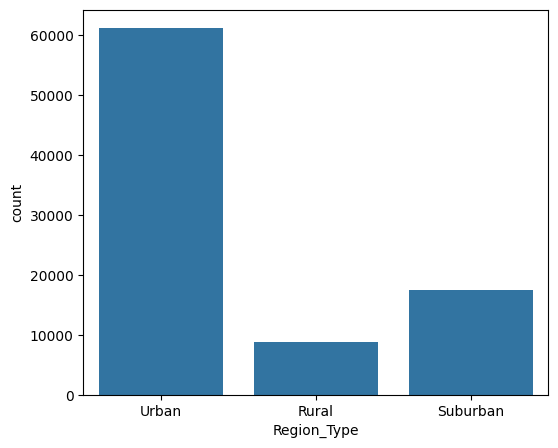

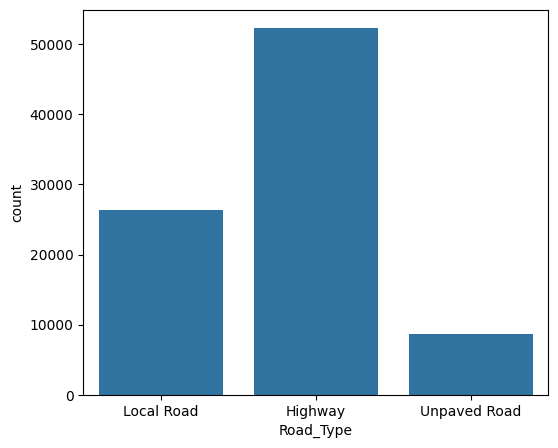

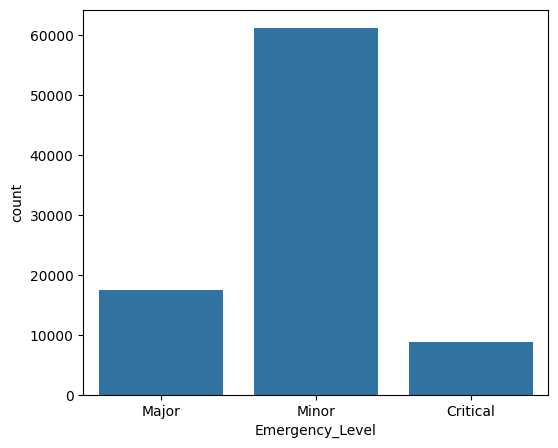

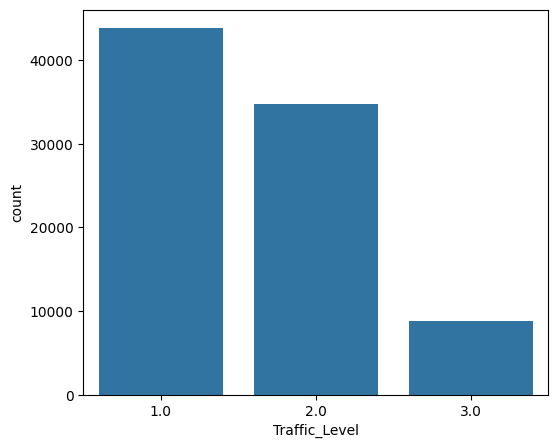

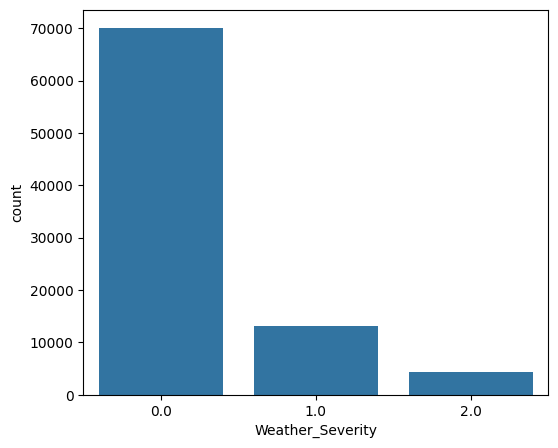

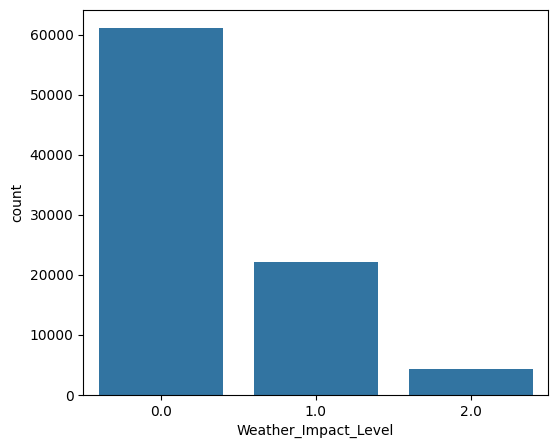

In [55]:
for c in cat_cols:
    plt.figure(figsize=(6,5))
    sns.countplot(x=df[c])
    plt.show()

1. most incidents are urban, on highways and have minor emergency level. 
2. traffic and weather are mostly low / clear

# Bivariate Analysis

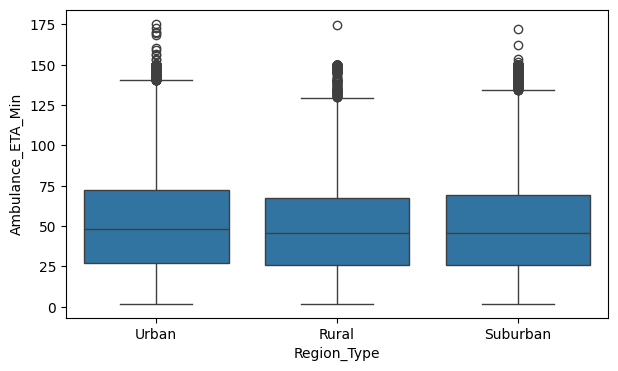

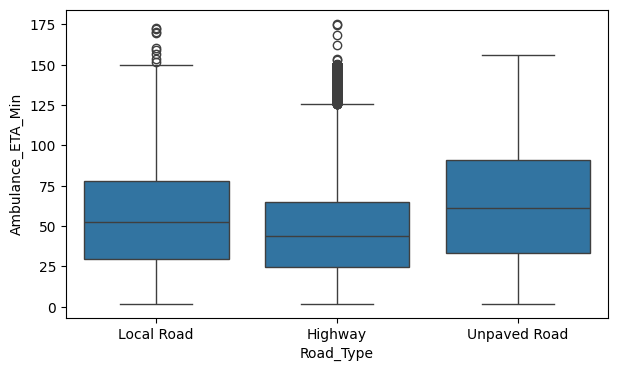

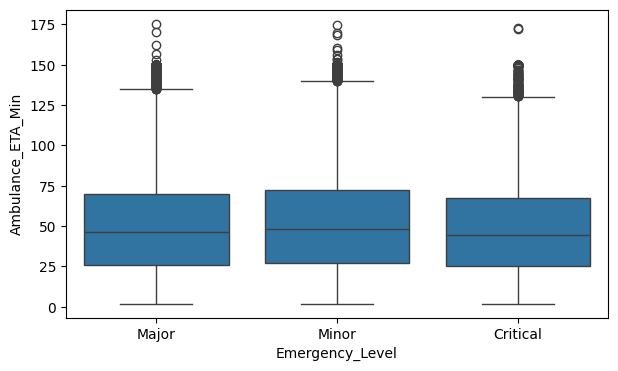

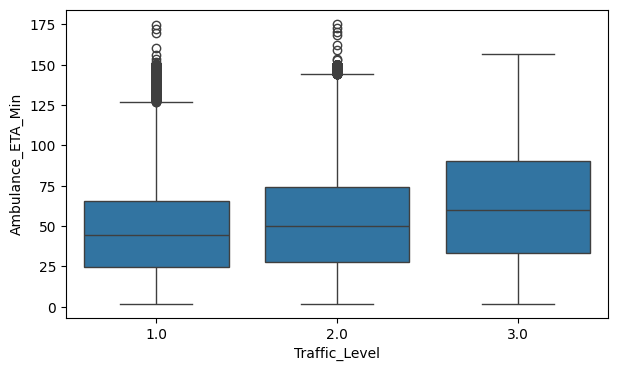

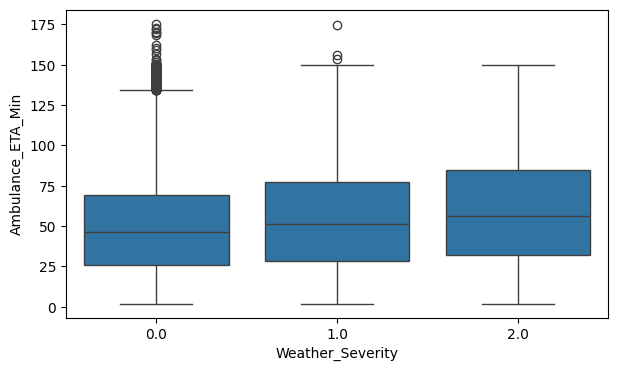

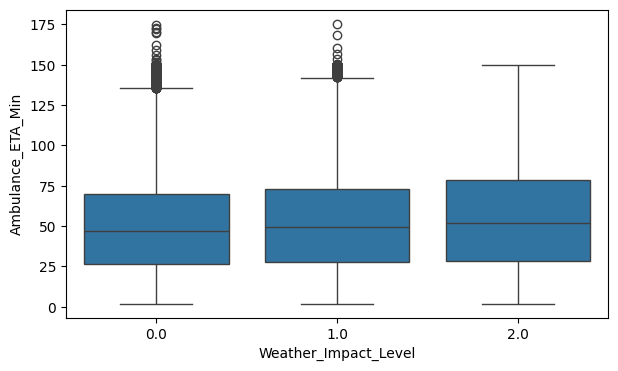

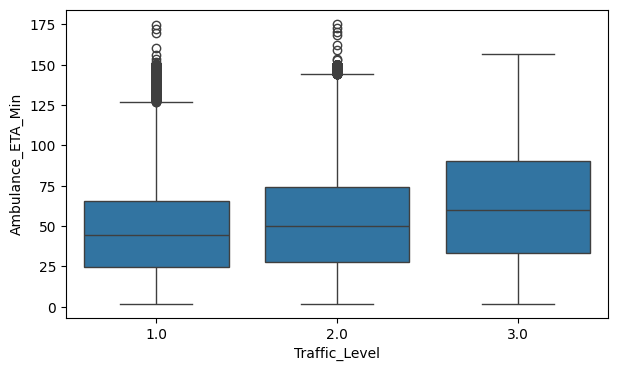

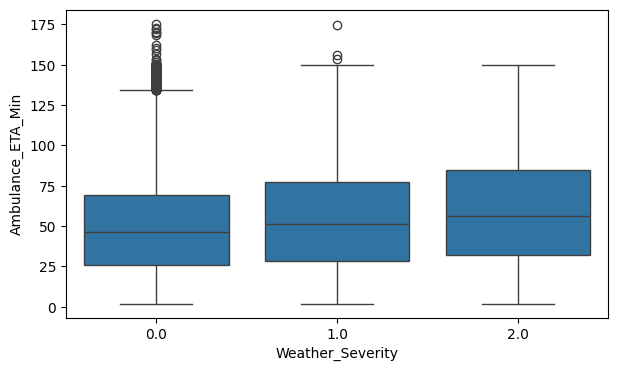

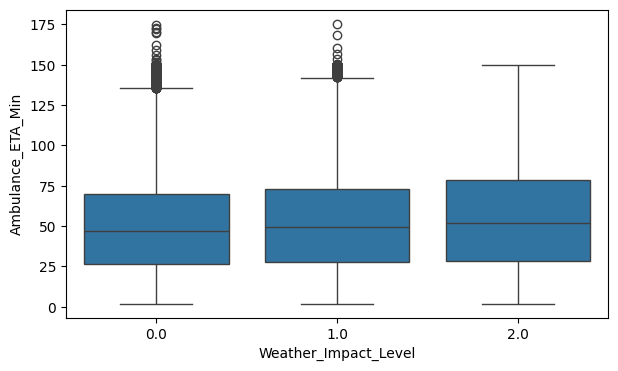

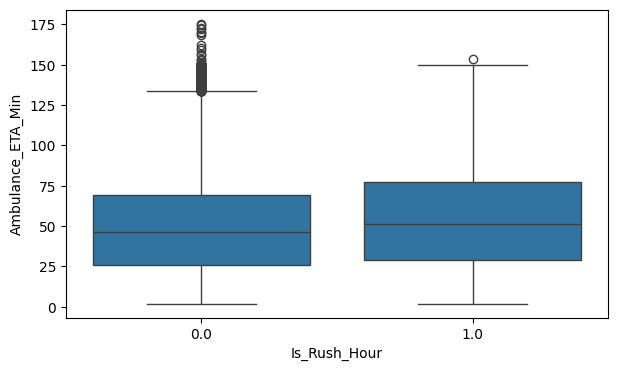

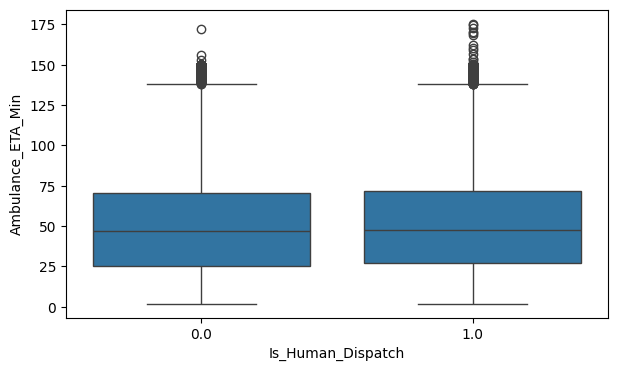

In [56]:
for c in cat_cols + ["Traffic_Level", "Weather_Severity", "Weather_Impact_Level", "Is_Rush_Hour", "Is_Human_Dispatch"]:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=c, y="Ambulance_ETA_Min", data=df)
    plt.show()

1. Road_Type vs. ETA: Unpaved roads produce a higher median ETA than Highways and Local Roads.

2. Traffic_Level vs. ETA: Median ETA increases stepwise from Level 1 (~45 min) to Level 2 (~50 min) to Level 3 (~60 min).

3. Weather_Severity vs. ETA: Severe weather (Level 2) shifts the median ETA upward by ~10 minutes 

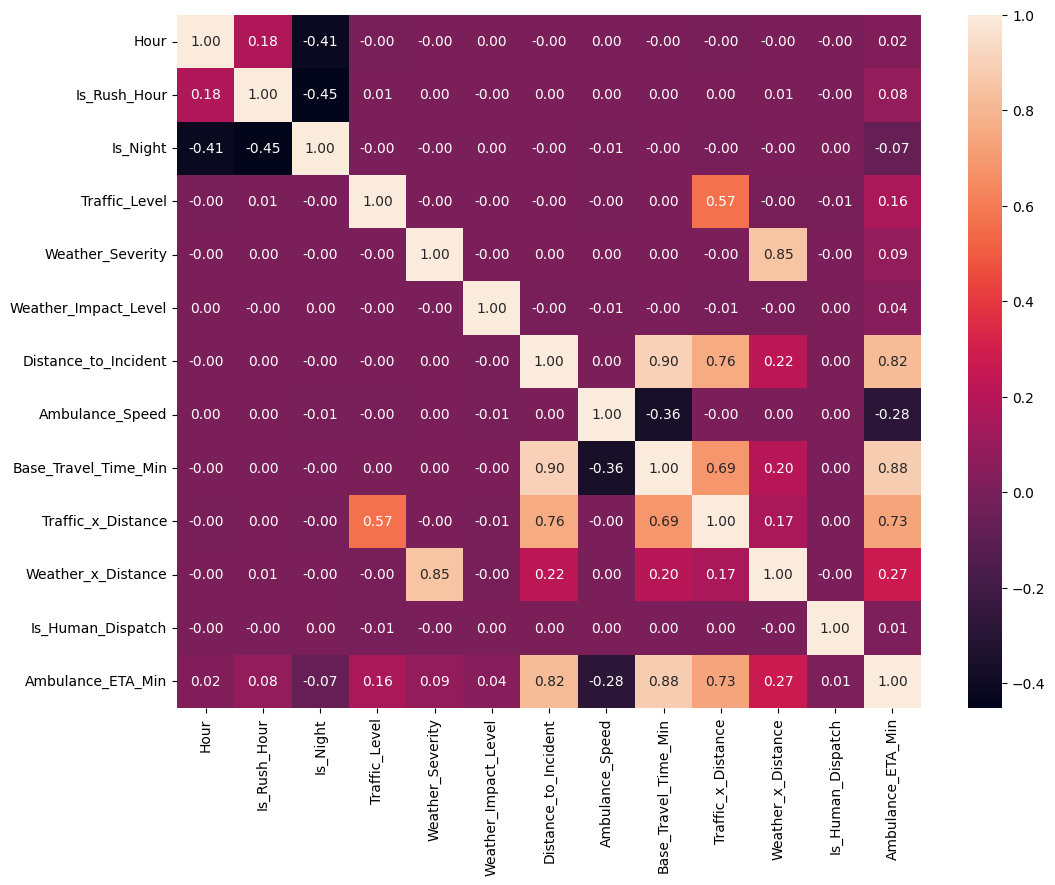

In [57]:
plt.figure(figsize=(12, 9))
sns.heatmap(df[num_col].corr(), annot=True, fmt=".2f")
plt.show()

1. Base_Travel_Time_Min displays the highest positive correlation with ETA (+0.88).

2. Distance_to_Incident ranks second (+0.82).

3. Traffic_x_Distance captures congestion bottlenecks (+0.73).

4. Ambulance_Speed exhibits an inverse correlation (-0.28), confirming faster speeds reduce overall arrival times.

# encode categorical columns

In [58]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
encoder = OneHotEncoder()
scaler = StandardScaler()

In [59]:
x = df.drop("Ambulance_ETA_Min", axis=1)
y = df["Ambulance_ETA_Min"]

In [60]:
non_num_col

Index(['Region_Type', 'Road_Type', 'Emergency_Level'], dtype='str')

In [61]:
x_enc = pd.get_dummies(x, columns=cat_cols, dtype=int)
x_enc.head()

,Hour,Is_Rush_Hour,Is_Night,Distance_to_Incident,Ambulance_Speed,Base_Travel_Time_Min,Traffic_x_Distance,Weather_x_Distance,Is_Human_Dispatch,Region_Type_Rural,...,Emergency_Level_Minor,Traffic_Level_1.0,Traffic_Level_2.0,Traffic_Level_3.0,Weather_Severity_0.0,Weather_Severity_1.0,Weather_Severity_2.0,Weather_Impact_Level_0.0,Weather_Impact_Level_1.0,Weather_Impact_Level_2.0
1,1.0,0.0,1,34.72,56.41,36.93,69.44,0.00,1.0,0,...,0,0,1,0,1,0,0,0,0,1
2,1.0,0.0,1,11.91,30.67,23.30,11.91,0.00,0.0,1,...,1,1,0,0,1,0,0,1,0,0
3,1.0,0.0,1,10.15,50.58,12.04,20.30,10.15,1.0,0,...,1,0,1,0,0,1,0,1,0,0
4,2.0,0.0,1,28.47,51.76,33.00,28.47,0.00,0.0,0,...,1,1,0,0,1,0,0,0,1,0
5,2.0,0.0,1,1.25,43.07,1.74,1.25,0.00,0.0,0,...,1,1,0,0,1,0,0,1,0,0


# split data

In [62]:
from sklearn.model_selection import train_test_split

In [63]:
x_train, x_test, y_train, y_test = train_test_split(x_enc, y, test_size=0.2, random_state=42)

In [64]:
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [65]:
results = {}

In [66]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [67]:
def evaluate(model, xt, xs):
    pred = model.predict(xs)
    return {
        "R2": r2_score(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
    }

In [68]:
lr = LinearRegression()
lr.fit(x_train_scaled, y_train)
results["Linear Regression"] = evaluate(lr, x_train_scaled, x_test_scaled)
results["Linear Regression"]

{'R2': 0.8721045253441935,
 'MAE': 8.3222501733742,
 'RMSE': np.float64(11.45427230208427)}

In [69]:
knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(x_train_scaled, y_train)
results["KNN"] = evaluate(knn, x_train_scaled, x_test_scaled)
results["KNN"]

{'R2': 0.82201146742814,
 'MAE': 9.756817043179868,
 'RMSE': np.float64(13.512506802991311)}

In [70]:
dt = DecisionTreeRegressor(random_state=42)
dt.fit(x_train, y_train)
results["Decision Tree"] = evaluate(dt, x_train, x_test)
results["Decision Tree"]

{'R2': 0.7499361203581345,
 'MAE': 11.312356305404633,
 'RMSE': np.float64(16.016418079353787)}

In [71]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)
results["Random Forest"] = evaluate(rf, x_train, x_test)
results["Random Forest"]

{'R2': 0.8729139553376997,
 'MAE': 8.133939748355733,
 'RMSE': np.float64(11.41796864264602)}

In [72]:
comparison = pd.DataFrame(results).T.reset_index().rename(columns={"index": "Model"})
comparison = comparison.sort_values("R2", ascending=False)
comparison

,Model,R2,MAE,RMSE
3,Random Forest,0.872914,8.133940,11.417969
0,Linear Regression,0.872105,8.322250,11.454272
1,KNN,0.822011,9.756817,13.512507
2,Decision Tree,0.749936,11.312356,16.016418


In [73]:
best = comparison.iloc[0]
print("Best model:", best["Model"], "| R2:", round(best["R2"], 4), "| MAE:", round(best["MAE"], 2), "min")

Best model: Random Forest | R2: 0.8729 | MAE: 8.13 min


# improving models 

In [74]:
from sklearn.model_selection import GridSearchCV

In [75]:
param_grid = {
    'alpha': [0.001, 0.01, 0.1, 1, 10, 100],
    'solver': ['auto', 'svd']
}
grid = GridSearchCV(
    estimator=Ridge(),
    param_grid=param_grid,
    cv=5,
    scoring='r2',
)

In [76]:
grid.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Ridge()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': [0.001, 0.01, ...], 'solver': ['auto', 'svd']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : the fold and candidate

In [77]:
grid.best_params_

{'alpha': 10, 'solver': 'auto'}

In [78]:
grid.best_score_

np.float64(0.8670325352174052)

In [79]:
param_grid_rf = {
    'n_estimators': [100],
    'max_depth': [6, 10, 15],
    'min_samples_leaf': [5, 20, 50],
}

In [80]:
grid_rf = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid_rf,
    cv=3,
    scoring='r2',
)

In [81]:
grid_rf.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [6, 10, ...], 'min_samples_leaf': [5, 20, ...], 'n_estimators': [100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the sc

In [82]:
grid_rf.best_params_

{'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 100}

In [83]:
grid_rf.best_score_


np.float64(0.8755563582919019)

In [84]:
best_rf = grid_rf.best_estimator_
print("Train R2:", r2_score(y_train, best_rf.predict(x_train)))
print("Test R2 :", r2_score(y_test, best_rf.predict(x_test)))
print("Test MAE:", mean_absolute_error(y_test, best_rf.predict(x_test)))

Train R2: 0.8944721522545416
Test R2 : 0.8783296397803684
Test MAE: 7.94641331462582


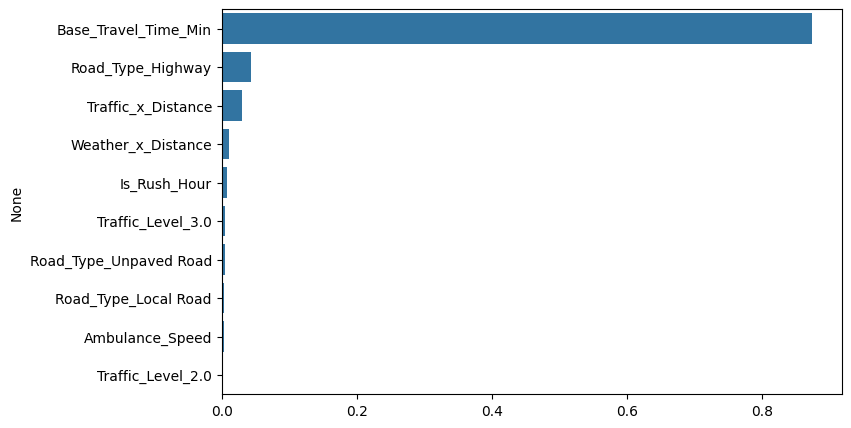

In [85]:
imp = pd.Series(best_rf.feature_importances_, index=x_train.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index)
plt.show()

# Building Pipeline 

In [86]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

In [149]:
df =pd.read_csv("ambulance_eta.csv")

In [150]:
df=df.drop_duplicates()

In [151]:
cat_cols = ['Region_Type', 'Road_Type', 'Emergency_Level',"Traffic_Level", "Weather_Severity", "Weather_Impact_Level"]

In [152]:
non_num_col = df.describe(include="object").columns

C:\Users\pushk\AppData\Local\Temp\ipykernel_4944\3156144658.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  non_num_col = df.describe(include="object").columns


In [153]:
for c in non_num_col:
    df[c] = df[c].str.strip().str.title()

In [154]:
df.columns[0]

'Unnamed: 0'

In [155]:
df = df.drop(df.columns[0],axis=1)

In [156]:
df["Road_Type"] = df["Road_Type"].replace({"Local Rd": "Local Road"})
df["Region_Type"] = df["Region_Type"].replace({"Sub-Urban": "Suburban"})

In [157]:
df.columns

Index(['Hour', 'Is_Rush_Hour', 'Is_Night', 'Traffic_Level', 'Weather_Severity',
       'Weather_Impact_Level', 'Distance_to_Incident', 'Ambulance_Speed',
       'Base_Travel_Time_Min', 'Traffic_x_Distance', 'Weather_x_Distance',
       'Is_Human_Dispatch', 'Ambulance_ETA_Min', 'Region_Type', 'Road_Type',
       'Emergency_Level'],
      dtype='str')

In [158]:
df.loc[(df["Distance_to_Incident"] <= 0) | (df["Distance_to_Incident"] > 60), "Distance_to_Incident"] = np.nan
df.loc[(df["Ambulance_Speed"] <= 0) | (df["Ambulance_Speed"] > 100), "Ambulance_Speed"] = np.nan
df.loc[~df["Hour"].between(0, 23), "Hour"] = np.nan
df.loc[~df["Traffic_Level"].isin([1, 2, 3]), "Traffic_Level"] = np.nan
df.loc[~df["Is_Rush_Hour"].isin([0, 1]), "Is_Rush_Hour"] = np.nan
df.loc[(df["Base_Travel_Time_Min"] <= 0) | (df["Base_Travel_Time_Min"] > 300), "Base_Travel_Time_Min"] = np.nan
df.loc[(df["Ambulance_ETA_Min"] <= 0) | (df["Ambulance_ETA_Min"] > 150), "Ambulance_ETA_Min"] = np.nan

In [159]:
df = df.replace(["", "Unknown", "N/A", "NA", "null", "?"], np.nan)

In [160]:
df=df.dropna()
df.shape

(87773, 16)

In [161]:
X = df.drop(columns=["Ambulance_ETA_Min"])
y = df["Ambulance_ETA_Min"]

In [162]:
num_col = x.describe().columns
cat_cols = x.describe(include="object").columns

C:\Users\pushk\AppData\Local\Temp\ipykernel_4944\3123032411.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = x.describe(include="object").columns


In [163]:
numerical_transformer = Pipeline([
    ("scaler",StandardScaler())
])
categorical_transformer = Pipeline([
    ("Onehot",OneHotEncoder(handle_unknown="ignore"))
])

In [164]:
preprocessor = ColumnTransformer([
    ("num", numerical_transformer, num_col),
    ("cat", categorical_transformer, cat_cols)
])

In [165]:
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(**grid_rf.best_params_, random_state=42, n_jobs=-1))
])

In [166]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [167]:
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers co

In [168]:
y_pred = pipeline.predict(X_test)

In [169]:
r2_score(y_test,y_pred)

0.8794587029675268

In [170]:
import joblib 
joblib.dump(pipeline,"pipeline.pkl")

['pipeline.pkl']